In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [7]:
df = pd.read_csv("credit_card.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [8]:
print("Column data types:")
display(df.dtypes.to_frame("Data Type"))

print("Missing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Count")
)

print("Duplicate rows:", df.duplicated().sum())

print("Descriptive statistics:")
display(df.describe().T)

Column data types:


,Data Type
CUST_ID,str
BALANCE,float64
BALANCE_FREQUENCY,float64
PURCHASES,float64
ONEOFF_PURCHASES,float64
INSTALLMENTS_PURCHASES,float64
CASH_ADVANCE,float64
PURCHASES_FREQUENCY,float64
ONEOFF_PURCHASES_FREQUENCY,float64
PURCHASES_INSTALLMENTS_FREQUENCY,float64


Missing values:


,Missing Count
MINIMUM_PAYMENTS,313
CREDIT_LIMIT,1
BALANCE,0
CUST_ID,0
BALANCE_FREQUENCY,0
PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0


Duplicate rows: 0
Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


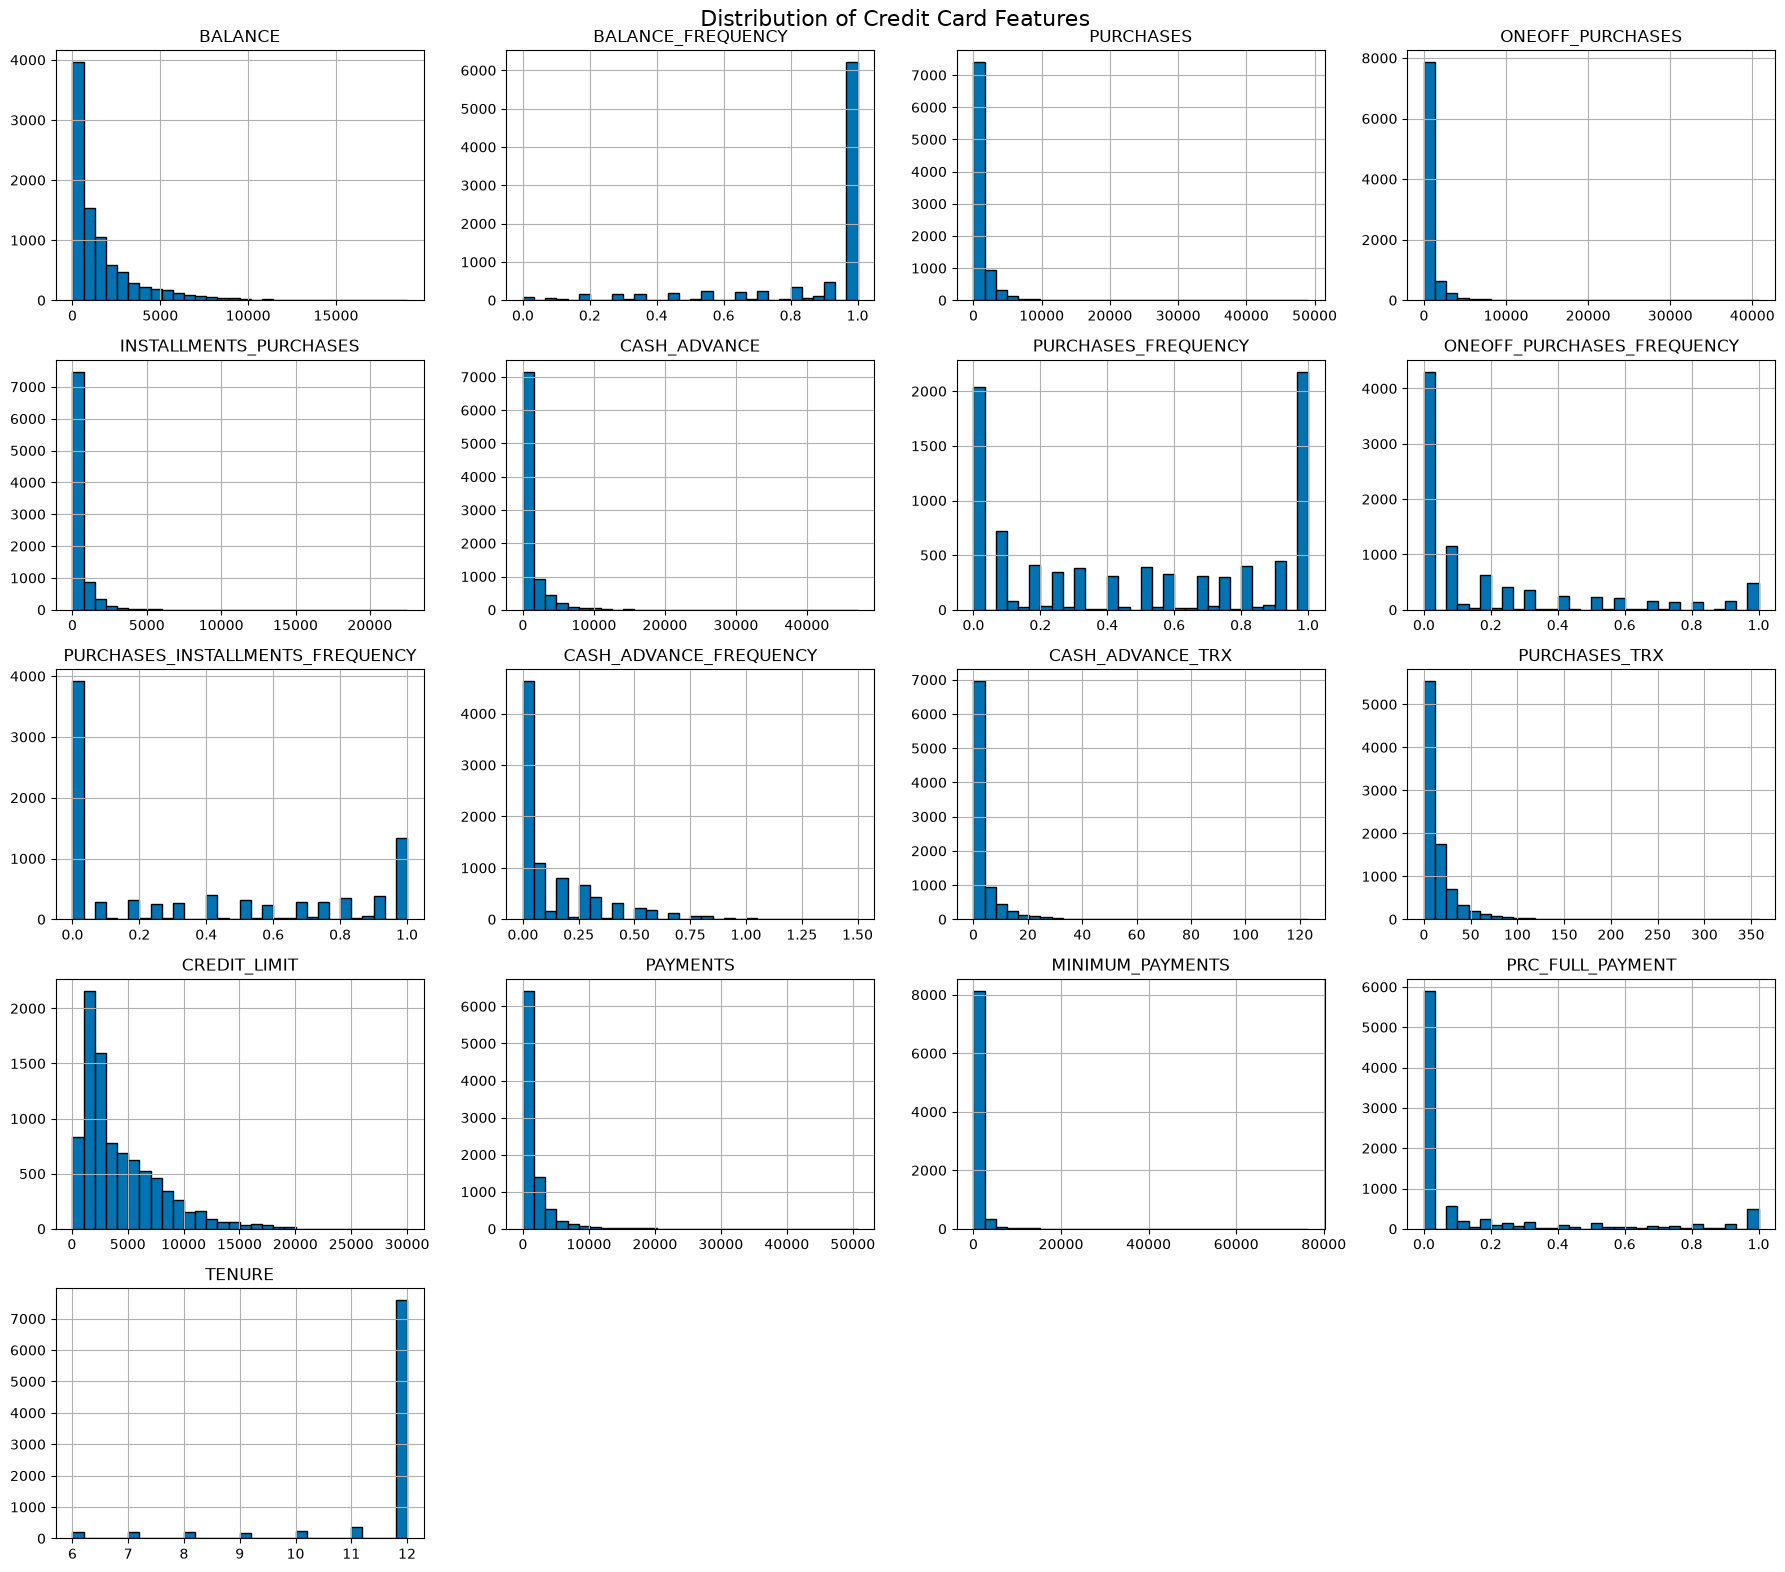

In [9]:
eda_df = df.drop(columns=["CUST_ID"], errors="ignore")
eda_df = eda_df.select_dtypes(include="number")

eda_df.hist(
    figsize=(18, 16),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Credit Card Features", fontsize=16)
plt.tight_layout()
plt.show()

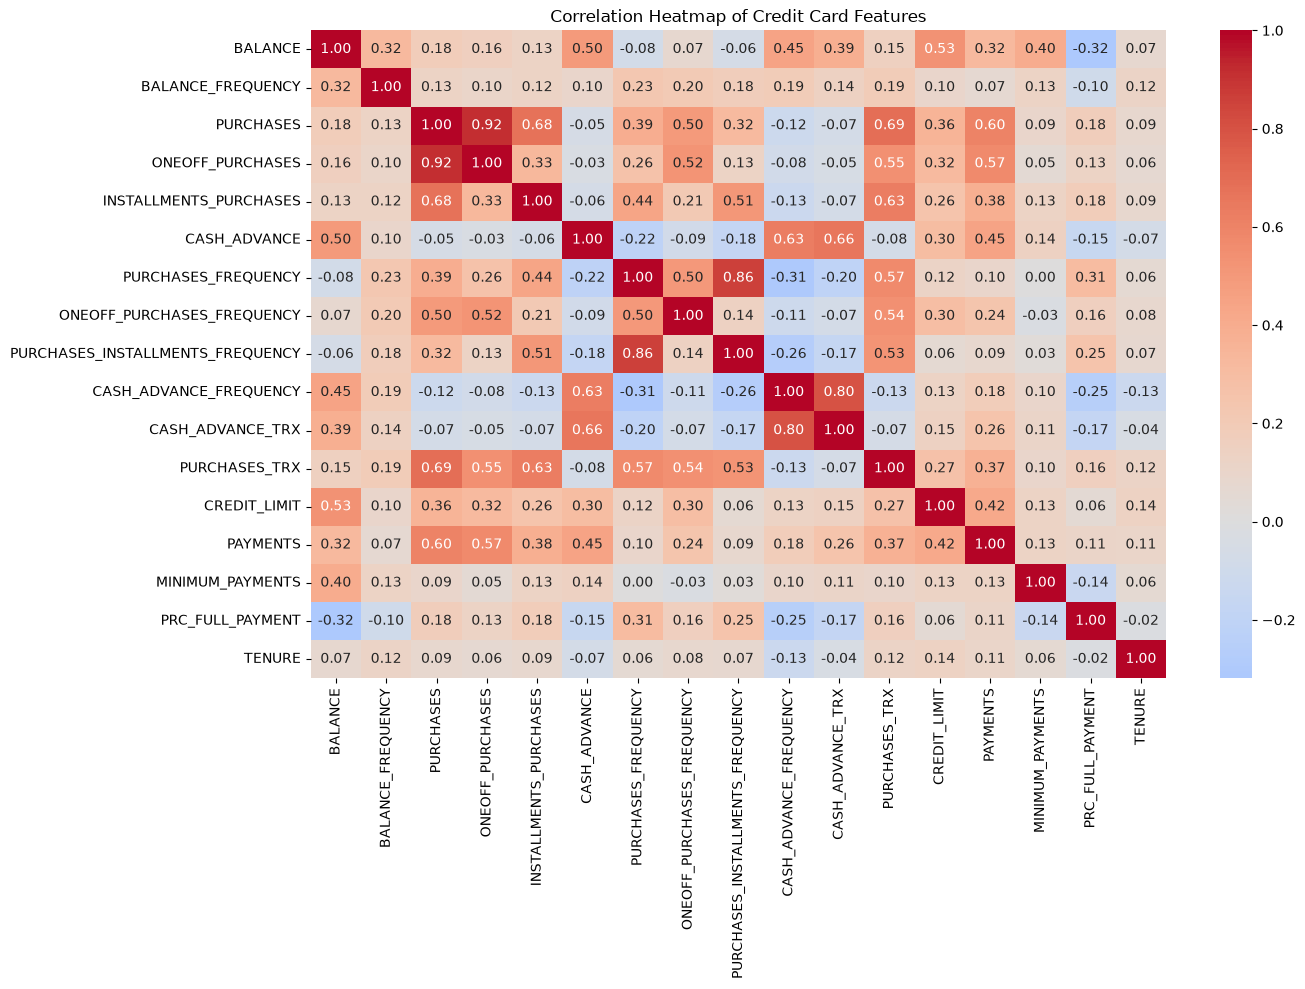

In [10]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    eda_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Credit Card Features")
plt.tight_layout()
plt.show()

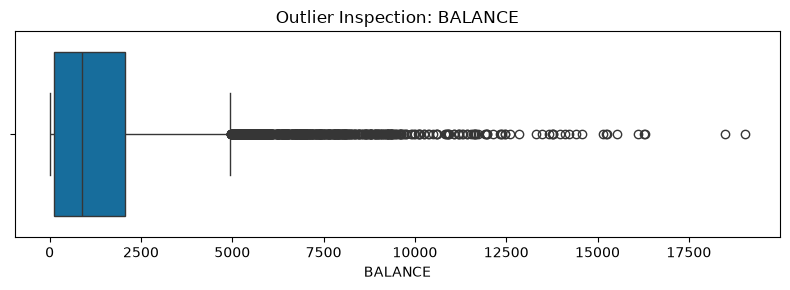

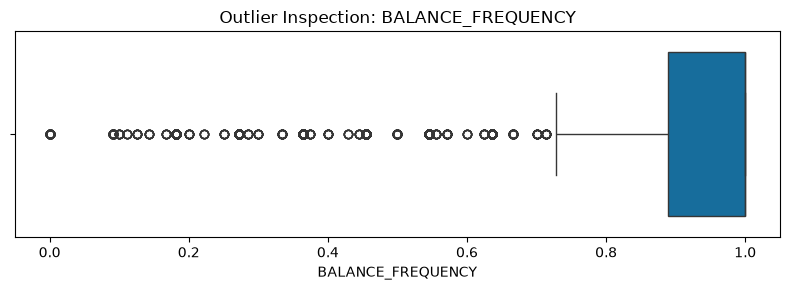

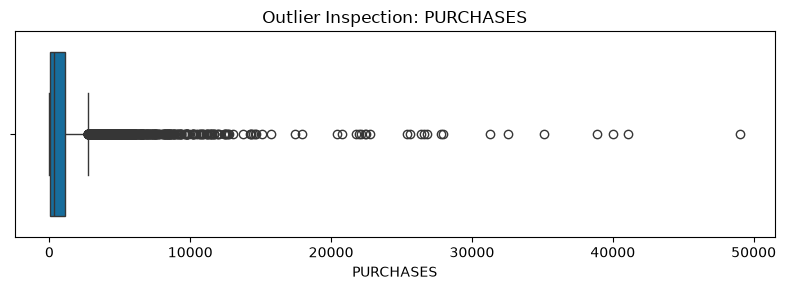

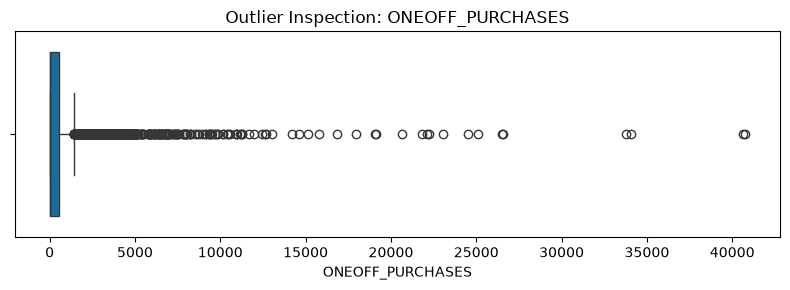

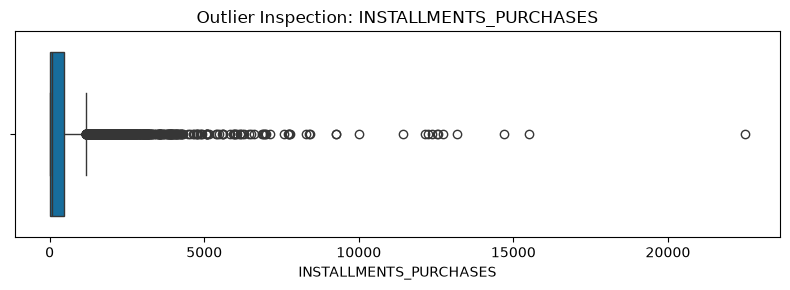

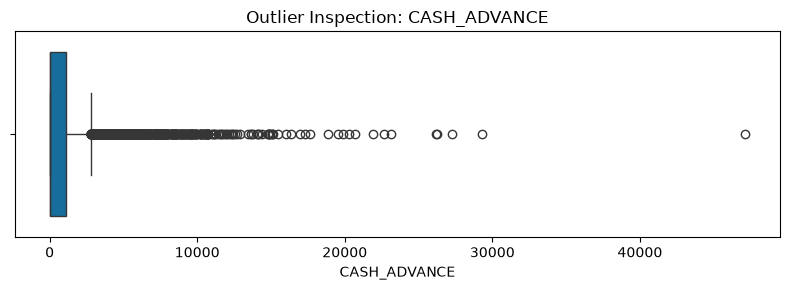

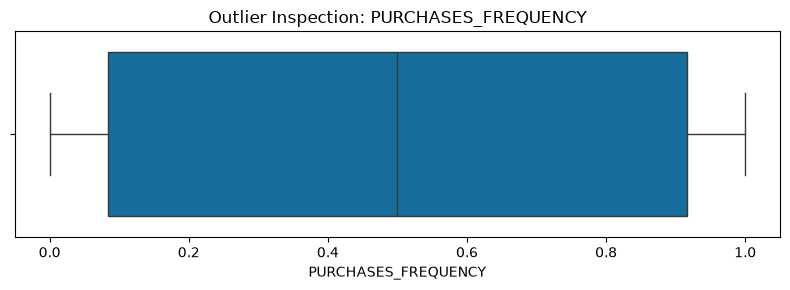

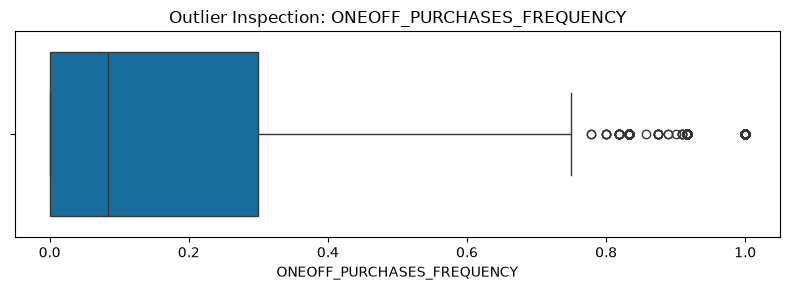

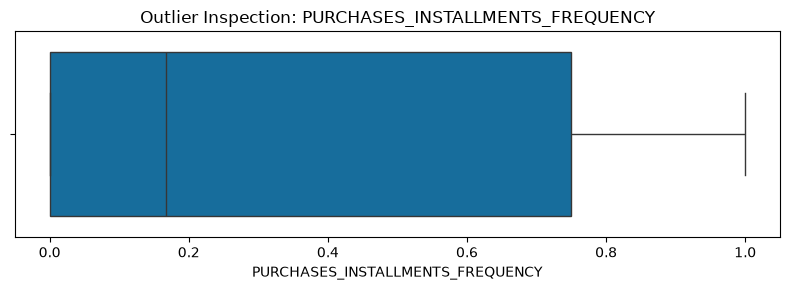

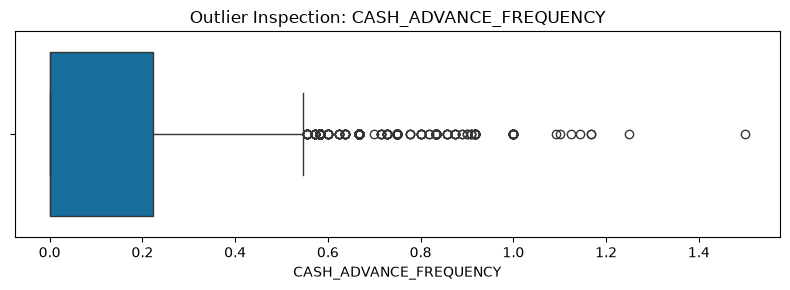

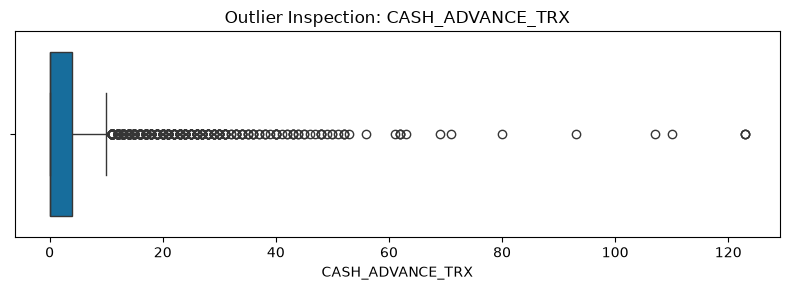

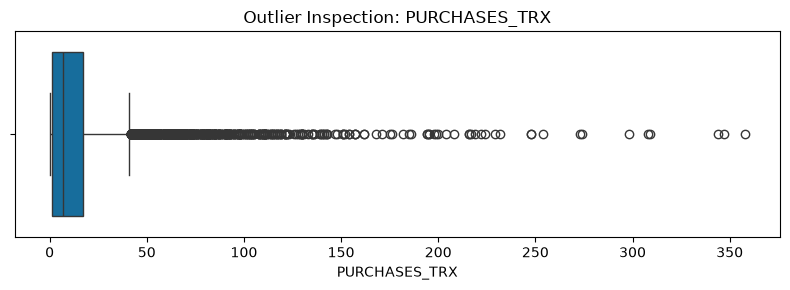

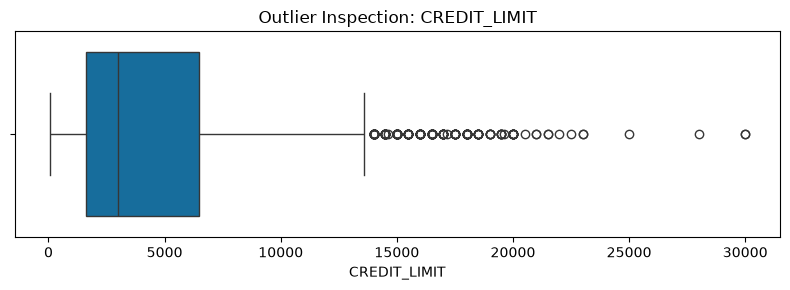

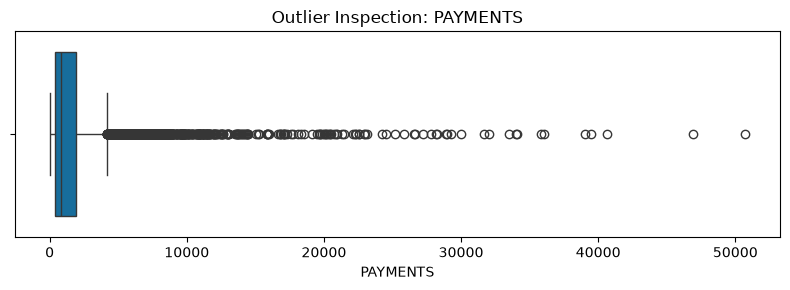

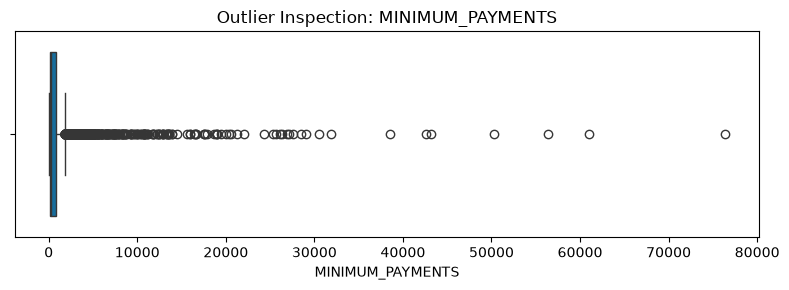

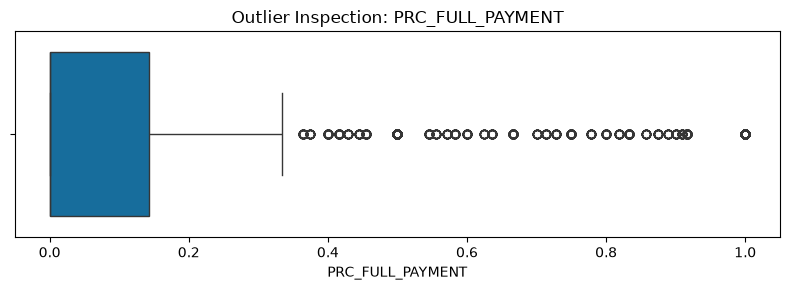

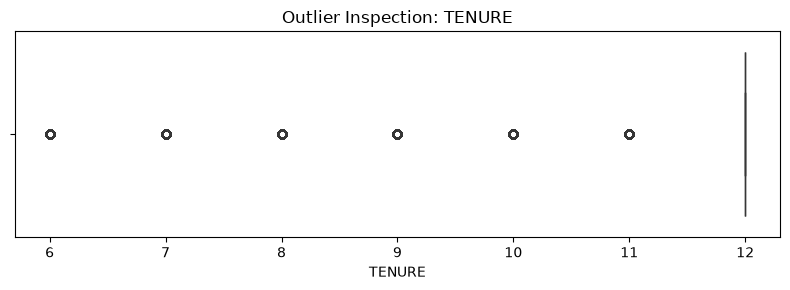

In [11]:
for col in eda_df.columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=eda_df[col])
    plt.title(f"Outlier Inspection: {col}")
    plt.tight_layout()
    plt.show()

In [12]:
# Remove customer identifier; it is not a behavioural feature.
X_raw = df.drop(columns=["CUST_ID"], errors="ignore").copy()

# Convert all features to numeric where possible.
X_raw = X_raw.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values.
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)

# Remove columns with no usable observations.
X_raw = X_raw.dropna(axis=1, how="all")

print("Remaining features:", X_raw.columns.tolist())
print("Missing values before imputation:", X_raw.isna().sum().sum())

Remaining features: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
Missing values before imputation: 314


In [15]:
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np

In [16]:
imputer = SimpleImputer(strategy="median")

X_clean = pd.DataFrame(
    imputer.fit_transform(X_raw),
    columns=X_raw.columns,
    index=X_raw.index
)

# Apply log1p only to non-negative features with strong right skew.
skewed_features = [
    col for col in X_clean.columns
    if (X_clean[col] >= 0).all() and X_clean[col].skew() > 1
]

for col in skewed_features:
    X_clean[col] = np.log1p(X_clean[col])

print("Log-transformed features:", skewed_features)
print("Missing values after imputation:", X_clean.isna().sum().sum())

Log-transformed features: ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'ONEOFF_PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT']
Missing values after imputation: 0


In [17]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_clean),
    columns=X_clean.columns,
    index=X_clean.index
)

assert X_scaled.isna().sum().sum() == 0
assert np.isfinite(X_scaled.to_numpy()).all()

print("Scaled dataset shape:", X_scaled.shape)
display(X_scaled.head())

Scaled dataset shape: (8950, 17)


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-1.205218,-0.249434,-0.113532,-0.987090,0.394480,-0.930733,-0.806490,-0.732480,-0.707313,-0.724360,-0.810069,-0.579510,-1.447163,-0.824484,-0.829841,-0.556368,0.36068
1,0.948918,0.134325,-1.679855,-0.987090,-1.087454,1.528788,-1.221758,-0.732480,-0.916995,0.699592,0.784603,-1.379210,0.926060,1.065033,0.908184,0.391958,0.36068
2,0.824993,0.518084,0.600727,1.062022,-1.087454,-0.930733,1.269843,2.466762,-0.916995,-0.724360,-0.810069,0.487865,1.010229,-0.119300,0.450407,-0.556368,0.36068
3,0.624653,-1.016953,0.827499,1.265778,-1.087454,0.564372,-1.014125,-0.363042,-0.916995,-0.213583,-0.123281,-0.874655,1.010229,-4.161996,-0.144271,-0.556368,0.36068
4,0.271260,0.518084,-0.708481,-0.114307,-1.087454,-0.930733,-1.014125,-0.363042,-0.916995,-0.724360,-0.810069,-0.874655,-1.224909,-0.064979,-0.351833,-0.556368,0.36068


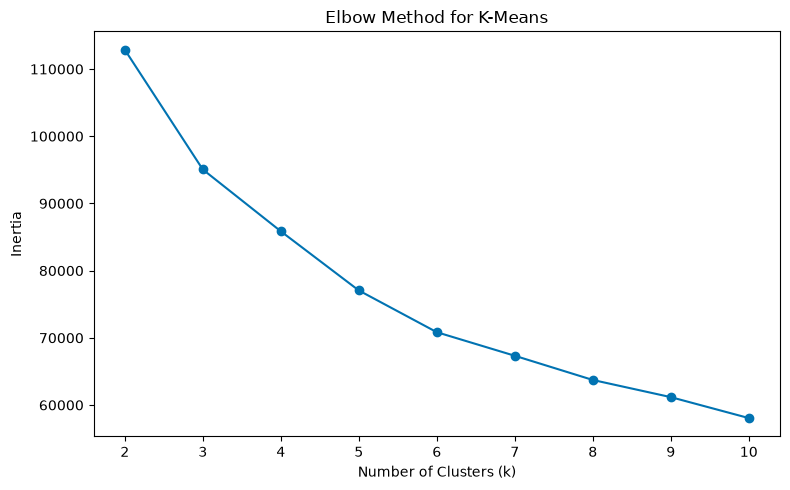

In [18]:
max_k = min(10, len(X_scaled) - 1)

if max_k < 2:
    raise ValueError("Not enough observations for clustering.")

k_values = range(2, max_k + 1)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [19]:
BEST_K = 4

kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means cluster counts:")
display(
    pd.Series(kmeans_labels, name="Cluster")
      .value_counts()
      .sort_index()
      .to_frame("Customers")
)

K-Means cluster counts:


,Customers
Cluster,
0,1923
1,3105
2,2393
3,1529


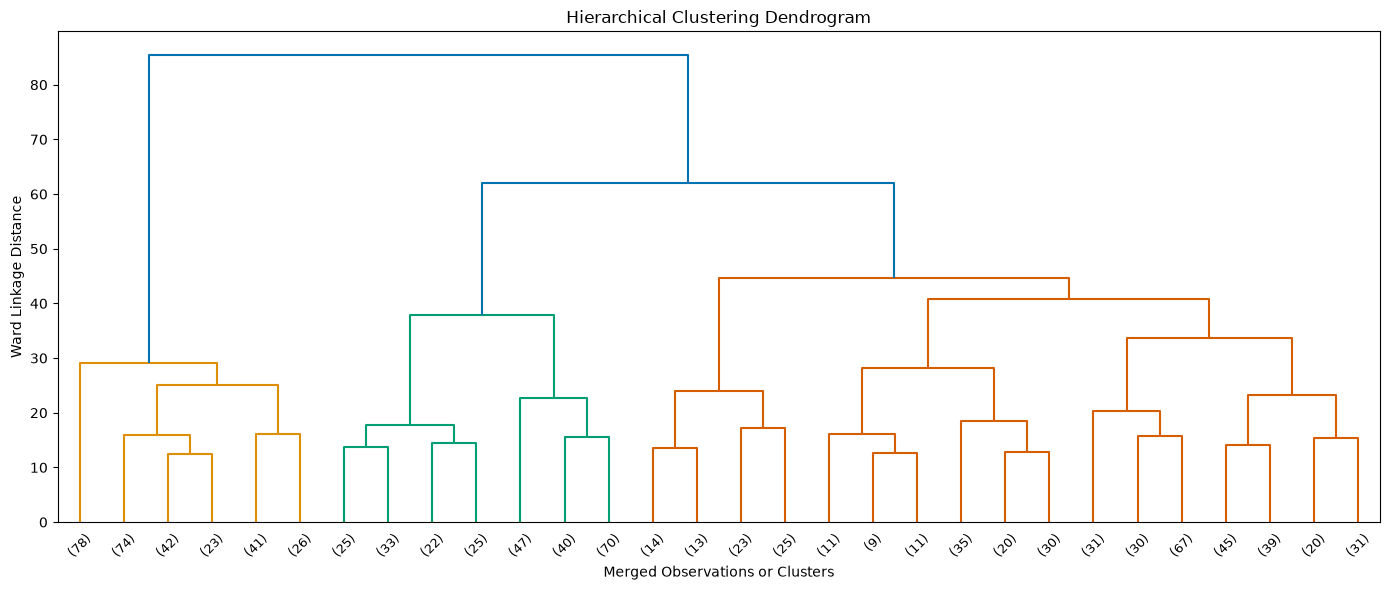

In [20]:
rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(1000, len(X_scaled))
sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_scaled.iloc[sample_indices]

linkage_matrix = linkage(
    X_sample.to_numpy(),
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=9
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Merged Observations or Clusters")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [21]:
hierarchical = AgglomerativeClustering(
    n_clusters=BEST_K,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical cluster counts:")
display(
    pd.Series(hierarchical_labels, name="Cluster")
      .value_counts()
      .sort_index()
      .to_frame("Customers")
)

Hierarchical cluster counts:


,Customers
Cluster,
0,2701
1,2245
2,1984
3,2020


In [22]:
def evaluate_model(X, labels, model_name):
    n_clusters = len(np.unique(labels))

    if not 2 <= n_clusters < len(labels):
        raise ValueError("Invalid number of clusters for evaluation.")

    return {
        "Algorithm": model_name,
        "Number of Clusters": n_clusters,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X, labels)
    }


results = pd.DataFrame([
    evaluate_model(X_scaled, kmeans_labels, "K-Means"),
    evaluate_model(
        X_scaled,
        hierarchical_labels,
        "Agglomerative Hierarchical"
    )
])

display(results.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,4,0.2150,1.6559,2302.5672
1,Agglomerative Hierarchical,4,0.1784,1.8456,1916.3725


In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Variance explained by two components: 56.27 %


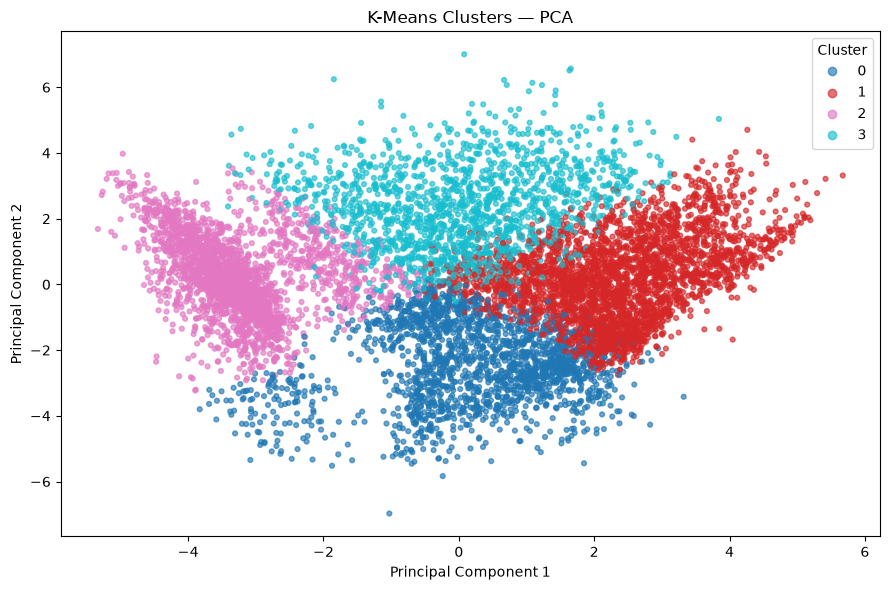

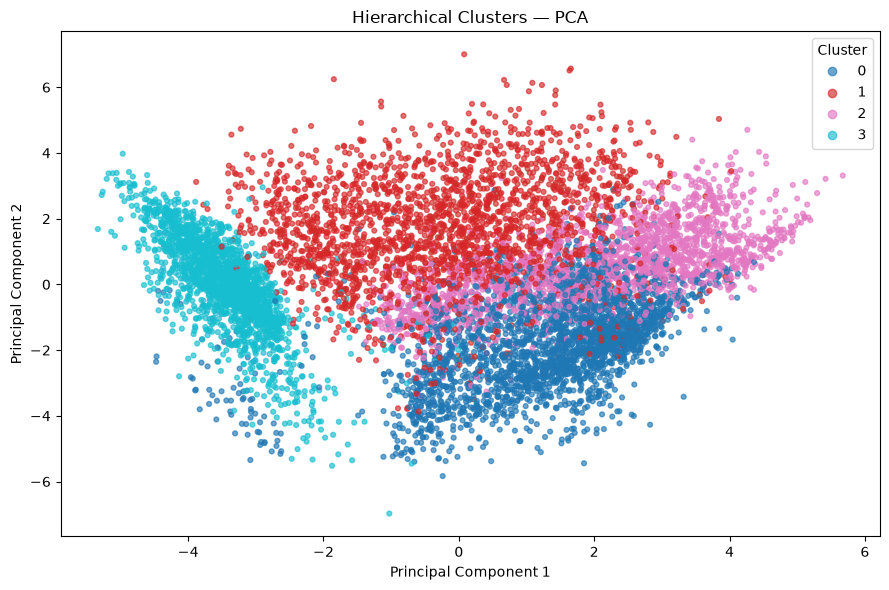

In [24]:
def plot_clusters_2d(components, labels, title):
    plt.figure(figsize=(9, 6))

    scatter = plt.scatter(
        components[:, 0],
        components[:, 1],
        c=labels,
        cmap="tab10",
        s=12,
        alpha=0.65
    )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title(title)
    plt.legend(
        *scatter.legend_elements(),
        title="Cluster",
        loc="best"
    )
    plt.tight_layout()
    plt.show()


plot_clusters_2d(X_pca, kmeans_labels, "K-Means Clusters — PCA")
plot_clusters_2d(
    X_pca,
    hierarchical_labels,
    "Hierarchical Clusters — PCA"
)

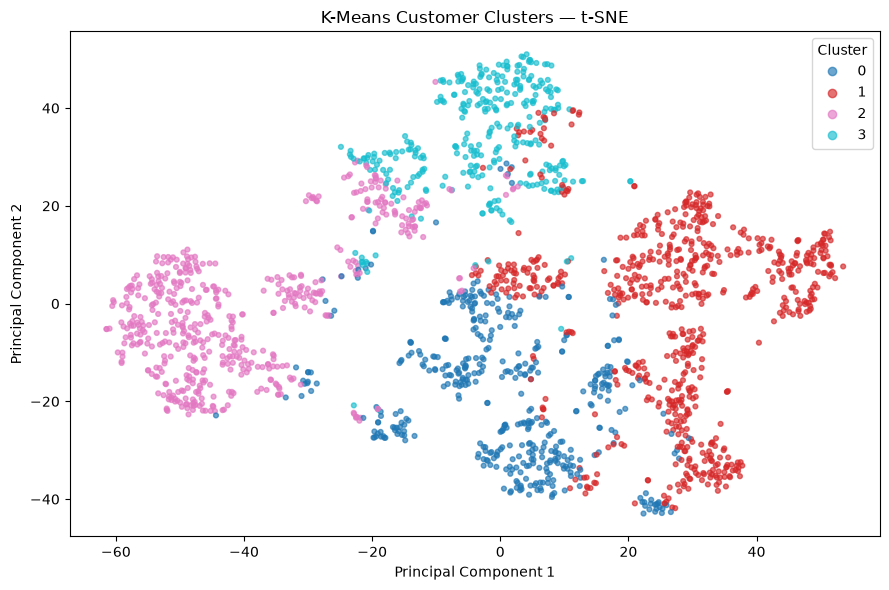

In [25]:
tsne_sample_size = min(2000, len(X_scaled))

tsne_indices = rng.choice(
    len(X_scaled),
    size=tsne_sample_size,
    replace=False
)

X_tsne_input = X_scaled.iloc[tsne_indices]
tsne_labels = kmeans_labels[tsne_indices]

tsne = TSNE(
    n_components=2,
    perplexity=min(30, tsne_sample_size - 1),
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_tsne_input)

plot_clusters_2d(
    X_tsne,
    tsne_labels,
    "K-Means Customer Clusters — t-SNE"
)

In [26]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

results.to_csv(output_dir / "clustering_metrics.csv", index=False)

cluster_assignments = pd.DataFrame({
    "CUST_ID": (
        df["CUST_ID"].values
        if "CUST_ID" in df.columns
        else df.index
    ),
    "KMeans_Cluster": kmeans_labels,
    "Hierarchical_Cluster": hierarchical_labels
})

cluster_assignments.to_csv(
    output_dir / "cluster_assignments.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
